# IS403 - Walmart M5: ARIMAX, SARIMAX and External-Feature Ablation

Test whether known calendar, event and SNAP inputs improve 28-day forecasts
of the audited Level 1 series. The error orders and deterministic trends are
frozen from notebook 03 before adding external regressors:

- ARIMA/ARIMAX: (7,1,2), with drift.
- SARIMA/SARIMAX: (1,1,1)(1,1,1) with weekly period 7, no deterministic trend.

This is a controlled feature ablation, not an exhaustive joint search over
regressors and ARIMA orders. Coefficients are refitted for each variant and
origin. Only `train.csv` and `val.csv` are opened; Test remains outside this work.

Run all cells on Kaggle CPU with the same processed dataset as notebooks 00-03.
No new data or path edits are required. Progress is printed for the 18
statistical fits. Each fit may take longer than a baseline calculation.

In [1]:
from pathlib import Path
from importlib import metadata
from datetime import datetime, timezone
from time import perf_counter
from zipfile import ZipFile, ZIP_DEFLATED
from itertools import product
import hashlib
import json
import platform
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.graphics.gofplots import qqplot
from threadpoolctl import threadpool_limits

DATA_DIR = None
OUTPUT_DIR = None

SEED = 42
HORIZON = 28
SEASON_LENGTH = 7
MA_WINDOWS = (7, 28)
ORIGINS = (1829, 1857, 1885)
SALES_SCALE = 1000.0
MAX_ITERATIONS = (200, 400)
ALPHA = 0.05
LB_LAGS = (56, 84, 112)
random.seed(SEED)
np.random.seed(SEED)
RUN_STARTED = perf_counter()

## 1. Verify Train/Validation and the common forecast origins

Every input value is checked against the audited fingerprints. The forecast
origins and RMSSE scales remain the same as notebooks 01 and 03. Target sales
are never included in the external-feature preprocessing inputs.

In [2]:
FILENAMES = ('train.csv', 'val.csv')


def find_data_directory(override=None):
    if override is not None:
        selected = Path(override).expanduser().resolve()
        if not all((selected / name).is_file() for name in FILENAMES):
            raise FileNotFoundError(f'Expected train.csv and val.csv in: {selected}')
        return selected

    candidates = set()
    for directory in [Path.cwd(), Path.cwd() / 'dataset',
                      Path.cwd() / '02_Data' / 'processed']:
        if all((directory / name).is_file() for name in FILENAMES):
            candidates.add(directory.resolve())

    root = Path('/kaggle/input')
    if root.is_dir():
        for path in root.rglob('train.csv'):
            if all((path.parent / name).is_file() for name in FILENAMES):
                candidates.add(path.parent.resolve())

    if not candidates:
        raise FileNotFoundError(
            'Attach the processed Kaggle dataset containing train.csv and val.csv, '
            'or set DATA_DIR explicitly.'
        )
    if len(candidates) > 1:
        options = '\n'.join(str(path) for path in sorted(candidates))
        raise ValueError(f'Multiple datasets found. Set DATA_DIR explicitly:\n{options}')
    return candidates.pop()


data_dir = find_data_directory(DATA_DIR)
output_dir = Path(OUTPUT_DIR) if OUTPUT_DIR is not None else (
    Path('/kaggle/working') if Path('/kaggle/working').is_dir()
    else Path.cwd() / 'arimax_output'
)
print(f'Data: {data_dir}')
print(f'Output: {output_dir.resolve()}')

Data: /kaggle/input/datasets/nhntrnc/is403-m5-level-1
Output: /kaggle/working


In [3]:
EXPECTED_COLUMNS = ['d', 'date', 'total_sales', 'weekday', 'wday_iso', 'month', 'year', 'event_name_1', 'event_type_1', 'event_name_2', 'event_type_2', 'snap_CA', 'snap_TX', 'snap_WI']
NUMERIC_COLUMNS = ['total_sales', 'wday_iso', 'month', 'year', 'snap_CA', 'snap_TX', 'snap_WI']
EVENT_COLUMNS = ['event_name_1', 'event_type_1', 'event_name_2', 'event_type_2']
REFERENCE_SHA256 = {'train': 'dcb9407590b16f6b975a1647c1c20f3cb932bc78dd75c1637f94d313c599d271', 'val': 'fbee2683fca3c5fc731b1d81829a56aa12c71e5b70ad124a1ac01ab3754536b5'}
SPLIT_DAYS = {'train': (1, 1885), 'val': (1886, 1913)}
FIRST_DATE = pd.Timestamp('2011-01-29')


def require(condition, message):
    if not condition:
        raise ValueError(message)


def table_sha256(frame):
    canonical_csv = frame[EXPECTED_COLUMNS].to_csv(index=False, lineterminator='\n')
    return hashlib.sha256(canonical_csv.encode('utf-8')).hexdigest()


def validate_split(name, directory):
    path = directory / f'{name}.csv'
    frame = pd.read_csv(path, keep_default_na=False)
    require(list(frame.columns) == EXPECTED_COLUMNS,
            f'{name}: columns or column order differ from the audited dataset.')

    first, last = SPLIT_DAYS[name]
    require(len(frame) == last - first + 1, f'{name}: incorrect row count.')
    require(frame['d'].tolist() == [f'd_{day}' for day in range(first, last + 1)],
            f'{name}: day IDs are missing, duplicated, or out of order.')
    dates = pd.to_datetime(frame['date'], format='%Y-%m-%d', errors='raise')
    expected_dates = pd.date_range(FIRST_DATE + pd.Timedelta(days=first - 1),
                                   periods=len(frame), freq='D')
    require(pd.DatetimeIndex(dates).equals(expected_dates),
            f'{name}: dates do not match the fixed chronological split.')
    require(not frame.duplicated(['d']).any() and not dates.duplicated().any(),
            f'{name}: duplicate day or date.')
    frame['date'] = dates.dt.strftime('%Y-%m-%d')

    for column in NUMERIC_COLUMNS:
        values = pd.to_numeric(frame[column], errors='raise')
        require(bool(np.isfinite(values.to_numpy()).all()),
                f'{name}: {column} contains missing or non-finite values.')
        require(bool((values % 1 == 0).all()), f'{name}: {column} must contain integers.')
        frame[column] = values.astype(np.int64)

    require(bool((frame['total_sales'] >= 0).all()), f'{name}: negative sales.')
    require(np.array_equal(frame['wday_iso'], dates.dt.dayofweek + 1),
            f'{name}: incorrect ISO weekday (Monday=1).')
    require(np.array_equal(frame['month'], dates.dt.month), f'{name}: incorrect month.')
    require(np.array_equal(frame['year'], dates.dt.year), f'{name}: incorrect year.')
    require(frame['weekday'].tolist() == dates.dt.day_name().tolist(),
            f'{name}: incorrect weekday names.')
    for column in ['snap_CA', 'snap_TX', 'snap_WI']:
        require(bool(frame[column].isin([0, 1]).all()), f'{name}: {column} is not binary.')
    for column in EVENT_COLUMNS:
        require(bool(frame[column].map(lambda value: isinstance(value, str)
                     and bool(value.strip())).all()),
                f'{name}: empty event labels; expected the literal string None.')

    fingerprint = table_sha256(frame)
    require(fingerprint == REFERENCE_SHA256[name],
            f'{name}: table values differ from the audited handoff. '
            'Use the audited original processed CSV files.')
    inventory = {
        'file': path.name,
        'rows': len(frame),
        'columns': len(frame.columns),
        'first_day': frame['d'].iloc[0],
        'last_day': frame['d'].iloc[-1],
        'first_date': frame['date'].iloc[0],
        'last_date': frame['date'].iloc[-1],
        'table_sha256': fingerprint,
        'matches_audited_handoff': True,
    }
    return frame, inventory

In [4]:
frames = {}
input_inventory = []
for split in SPLIT_DAYS:
    frames[split], record = validate_split(split, data_dir)
    input_inventory.append(record)

development = pd.concat([frames['train'], frames['val']], ignore_index=True)
require(len(development) == 1913, 'Expected exactly 1,913 development days.')
require(development['d'].tolist() == [f'd_{day}' for day in range(1, 1914)],
        'Development data must be consecutive and end at d_1913.')
development['date'] = pd.to_datetime(development['date'])

fold_plan = pd.DataFrame([
    {
        'fold': fold,
        'origin_day': f'd_{origin}',
        'origin_date': development.iloc[origin - 1]['date'].strftime('%Y-%m-%d'),
        'history_rows': origin,
        'forecast_start': development.iloc[origin]['date'].strftime('%Y-%m-%d'),
        'forecast_end': development.iloc[origin + HORIZON - 1]['date'].strftime('%Y-%m-%d'),
    }
    for fold, origin in enumerate(ORIGINS, start=1)
])
print(pd.DataFrame(input_inventory)[['file', 'rows', 'columns',
                                    'matches_audited_handoff']].to_string(index=False))
print(fold_plan.to_string(index=False))
print('PASS: development data verified; test.csv has not been read.')

     file  rows  columns  matches_audited_handoff
train.csv  1885       14                     True
  val.csv    28       14                     True
 fold origin_day origin_date  history_rows forecast_start forecast_end
    1     d_1829  2016-01-31          1829     2016-02-01   2016-02-28
    2     d_1857  2016-02-28          1857     2016-02-29   2016-03-27
    3     d_1885  2016-03-27          1885     2016-03-28   2016-04-24
PASS: development data verified; test.csv has not been read.


In [5]:
CONFIGS = [
    {'model': 'Naive', 'config_id': 'naive', 'window': 0, 'season_length': 0},
    {'model': 'Seasonal Naive', 'config_id': 'seasonal_naive_7',
     'window': 0, 'season_length': SEASON_LENGTH},
] + [
    {'model': 'Moving Average', 'config_id': f'moving_average_{window}',
     'window': window, 'season_length': 0}
    for window in MA_WINDOWS
]


def predict_baseline(history, config, horizon=HORIZON):
    """Return a fixed-origin forecast using observed history only."""
    history = np.asarray(history, dtype=np.float64)
    require(history.ndim == 1 and len(history) >= 2,
            'History must be a one-dimensional series with at least two observations.')
    require(np.isfinite(history).all(), 'History must contain finite values.')
    require(horizon > 0, 'Forecast horizon must be positive.')

    if config['model'] == 'Naive':
        prediction = np.full(horizon, history[-1], dtype=np.float64)
    elif config['model'] == 'Seasonal Naive':
        period = config['season_length']
        require(0 < period <= len(history), 'Invalid seasonal period.')
        prediction = np.tile(history[-period:], int(np.ceil(horizon / period)))[:horizon]
    elif config['model'] == 'Moving Average':
        window = config['window']
        require(0 < window <= len(history), 'Invalid averaging window.')
        prediction = np.full(horizon, history[-window:].mean(), dtype=np.float64)
    else:
        raise ValueError(f'Unknown model: {config["model"]}')

    require(prediction.shape == (horizon,) and np.isfinite(prediction).all(),
            'The forecast must contain exactly one finite value per target day.')
    clipped_count = int((prediction < 0).sum())
    return np.maximum(prediction, 0.0), clipped_count


def score_forecast(actual, prediction, history):
    actual = np.asarray(actual, dtype=np.float64)
    prediction = np.asarray(prediction, dtype=np.float64)
    history = np.asarray(history, dtype=np.float64)
    require(actual.shape == prediction.shape == (HORIZON,),
            'Each evaluation block must contain exactly 28 actuals and forecasts.')
    require(np.isfinite(actual).all() and np.isfinite(prediction).all(),
            'Scoring inputs must be finite.')
    require(history.ndim == 1 and len(history) >= 2 and np.isfinite(history).all(),
            'The RMSSE history must be a finite one-dimensional prefix.')
    scale = float(np.mean(np.diff(history) ** 2))
    require(np.isfinite(scale) and scale > 0, 'The RMSSE denominator must be positive.')
    error = actual - prediction
    mse = float(np.mean(error ** 2))
    return {
        'rmsse': float(np.sqrt(mse / scale)),
        'mae': float(np.mean(np.abs(error))),
        'rmse': float(np.sqrt(mse)),
        'rmsse_scale': scale,
    }

In [6]:
BASE_CONFIGS = [{'family': 'ARIMA', 'config_id': 'arima_7_1_2_t', 'p': 7, 'd': 1, 'q': 2, 'P': 0, 'D': 0, 'Q': 0, 's': 0, 'trend': 't'}, {'family': 'SARIMA', 'config_id': 'sarima_1_1_1_1_1_1_7_n', 'p': 1, 'd': 1, 'q': 1, 'P': 1, 'D': 1, 'Q': 1, 's': 7, 'trend': 'n'}]

SOURCE_CONFIG_SHA256 = '5797feb363e751c3785068362ff37d13e768ccc9a7c5d5f60acb5c9cb77c99a8'
require(BASE_CONFIGS[0]['p'] == 7 and BASE_CONFIGS[0]['trend'] == 't',
        'Expected the approved p=7 ARIMA with drift.')
print(pd.DataFrame(BASE_CONFIGS).to_string(index=False))

family              config_id  p  d  q  P  D  Q  s trend
 ARIMA          arima_7_1_2_t  7  1  2  0  0  0  0     t
SARIMA sarima_1_1_1_1_1_1_7_n  1  1  1  1  1  1  7     n


## 2. Define the feature ablation and fit preprocessing on history only

| Feature set | Available inputs |
|---|---|
| history_only | No external regressors; the frozen ARIMA/SARIMA reference. |
| calendar_events | Six weekday indicators, month sine/cosine, and event-name indicators. |
| calendar_events_snap | The preceding set plus separate SNAP flags for CA, TX and WI. |

An event indicator is one when its name appears in either event slot. Event
vocabulary is learned only from the current training prefix. Future unseen
names map to zero indicators and are reported. Calendar information and SNAP
for the forecast dates are known inputs, not future sales observations.

Before estimation, check identification after the model's specified ordinary
and seasonal differencing. Columns annihilated by differencing or dependent on
earlier retained columns/the deterministic trend are removed and logged.
In particular, exactly weekly weekday indicators vanish under seasonal
differencing at lag 7, so their separate coefficients are not estimated for
the frozen SARIMA error specification. The weekly structure remains in the
seasonal model. This is an identification constraint, not evidence of zero
business importance.

Retained regressors are standardized with means and population standard
deviations fitted on the observed prefix only. The same numbers transform
the 28 future rows. This improves numerical conditioning of rare event dummies.
The sales target uses the fixed unit divisor 1,000, as in notebook 03.

In [7]:
EXOG_INPUT_COLUMNS = ['wday_iso', 'month', 'event_name_1', 'event_name_2',
                      'snap_CA', 'snap_TX', 'snap_WI']
FEATURE_GROUPS = ['history_only', 'calendar_events', 'calendar_events_snap']


def difference_design(values, config):
    result = np.asarray(values, dtype=np.float64)
    for _ in range(config['d']):
        result = np.diff(result, axis=0)
    for _ in range(config['D']):
        result = result[config['s']:] - result[:-config['s']]
    return result


def make_feature_table(inputs, event_names, feature_group):
    if list(inputs.columns) != EXOG_INPUT_COLUMNS:
        raise ValueError('Exogenous inputs must contain only the declared calendar columns.')
    values = {}
    for weekday in range(2, 8):
        values[f'weekday_{weekday}'] = (inputs['wday_iso'].to_numpy() == weekday).astype(float)
    angle = 2 * np.pi * (inputs['month'].to_numpy(dtype=float) - 1) / 12
    values['month_sin'] = np.sin(angle)
    values['month_cos'] = np.cos(angle)
    if feature_group in ['calendar_events', 'calendar_events_snap']:
        first = inputs['event_name_1'].to_numpy()
        second = inputs['event_name_2'].to_numpy()
        for event in event_names:
            values[f'event__{event}'] = ((first == event) | (second == event)).astype(float)
    if feature_group == 'calendar_events_snap':
        for column in ['snap_CA', 'snap_TX', 'snap_WI']:
            values[column] = inputs[column].to_numpy(dtype=float)
    result = pd.DataFrame(values)
    if not np.isfinite(result.to_numpy()).all():
        raise ValueError('Non-finite calendar feature values.')
    return result


def prepare_exogenous(history_inputs, future_inputs, config, feature_group):
    if list(history_inputs.columns) != EXOG_INPUT_COLUMNS or list(future_inputs.columns) != EXOG_INPUT_COLUMNS:
        raise ValueError('Target sales must not enter exogenous preprocessing.')
    if feature_group == 'history_only':
        return None, None, {'feature_group': feature_group, 'event_vocabulary': [],
                            'retained_columns': [], 'dropped_columns': [],
                            'unseen_future_events': [], 'raw_columns': [],
                            'fit_rows': len(history_inputs)}
    vocabulary = sorted({value for column in ['event_name_1', 'event_name_2']
                         for value in history_inputs[column].unique() if value != 'None'})
    train_raw = make_feature_table(history_inputs, vocabulary, feature_group)
    future_raw = make_feature_table(future_inputs, vocabulary, feature_group)
    differenced = difference_design(train_raw.to_numpy(), config)
    deterministic = np.arange(1.0, len(history_inputs) + 1).reshape(-1, 1)
    basis = difference_design(deterministic, config) if config['trend'] == 't' else np.empty((len(differenced), 0))
    retained, dropped = [], []
    with threadpool_limits(limits=1):
        for index, column in enumerate(train_raw.columns):
            vector = differenced[:, index]
            norm = np.linalg.norm(vector)
            if norm <= 1e-9:
                dropped.append({'feature': column, 'reason': 'zero after model differencing'})
                continue
            residual = vector - basis @ np.linalg.lstsq(basis, vector, rcond=None)[0] if basis.shape[1] else vector
            if np.linalg.norm(residual) <= 1e-9 * max(1.0, norm):
                dropped.append({'feature': column, 'reason': 'dependent after model differencing'})
                continue
            retained.append(column)
            basis = np.column_stack([basis, vector])
    if not retained:
        raise ValueError('No identifiable external regressors remain.')
    future_events = {value for column in ['event_name_1', 'event_name_2']
                     for value in future_inputs[column].unique() if value != 'None'}
    schema = {'feature_group': feature_group, 'event_vocabulary': vocabulary,
              'retained_columns': retained, 'dropped_columns': dropped,
              'unseen_future_events': sorted(future_events - set(vocabulary)),
              'raw_columns': list(train_raw.columns), 'fit_rows': len(history_inputs)}
    means = train_raw[retained].mean()
    scales = train_raw[retained].std(ddof=0)
    if not (scales > 1e-12).all():
        raise ValueError('A retained external regressor has zero training variance.')
    schema['scaling'] = {column: {'mean': float(means[column]), 'scale': float(scales[column])}
                         for column in retained}
    return (train_raw[retained] - means) / scales, (future_raw[retained] - means) / scales, schema

## 3. Fit the controlled model variants

The same maximum-likelihood state-space procedure, stationarity/invertibility
constraints and bounded optimizer retries are used across feature sets.
Every forecast is issued from a fixed origin using only its observed prefix
and known future external variables. Forecasts are restored to original units
and clipped at zero before scoring; clipping is counted.

Reference models are refitted using the frozen orders and trends, not their
old coefficients. Small numerical optimizer differences from notebook 03 can
occur; the ablation comparisons below use the current common run. Convergence,
warnings, runtime and information criteria are retained for every fit. A failed
fit receives no invented metrics or predictions.

In [8]:
def fit_exogenous_model(history, config, exog_train=None, exog_future=None):
    observed = np.asarray(history, dtype=np.float64)
    require(observed.ndim == 1 and len(observed) >= 100,
            'ARIMA requires a one-dimensional observed training prefix.')
    require(np.isfinite(observed).all(), 'Non-finite training observations.')
    started = perf_counter()
    messages = []
    fitted = None
    attempts = 0
    result = {'eligible': False, 'converged': False, 'attempts': 0,
              'fit_seconds': 0.0, 'aic': None, 'bic': None,
              'parameter_count': None, 'clipped_count': None,
              'clipped_fraction': None, 'warnings': '', 'error': ''}
    try:
        model = ARIMA(observed / SALES_SCALE, exog=exog_train,
                      order=(config['p'], config['d'], config['q']),
                      seasonal_order=(config['P'], config['D'], config['Q'], config['s']),
                      trend=config['trend'], enforce_stationarity=True,
                      enforce_invertibility=True)
        start_params = None
        for attempts, maxiter in enumerate(MAX_ITERATIONS, start=1):
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter('always')
                with threadpool_limits(limits=1):
                    fitted = model.fit(
                        start_params=start_params, method='statespace', cov_type='opg',
                        method_kwargs={'method': 'lbfgs', 'maxiter': maxiter, 'disp': False})
            messages.extend(f"attempt {attempts}: {type(w.message).__name__}: {w.message}"
                            for w in caught)
            result['converged'] = bool(fitted.mle_retvals.get('converged', False))
            if result['converged']:
                break
            if not np.isfinite(fitted.params).all():
                break
            start_params = fitted.params
        result.update(aic=float(fitted.aic), bic=float(fitted.bic),
                      parameter_count=int(len(fitted.params)))
        require(result['converged'], 'Optimizer did not converge after the allowed attempts.')
        require(np.isfinite(fitted.params).all()
                and np.isfinite([fitted.aic, fitted.bic]).all(),
                'Non-finite fitted parameters or information criteria.')
        raw = np.asarray(fitted.forecast(steps=HORIZON, exog=exog_future), dtype=np.float64) * SALES_SCALE
        require(raw.shape == (HORIZON,) and np.isfinite(raw).all(),
                'The forecast must have 28 finite values.')
        clipped = int((raw < 0).sum())
        result.update(eligible=True, clipped_count=clipped,
                      clipped_fraction=clipped / HORIZON)
        prediction = np.maximum(raw, 0.0)
    except Exception as error:
        result['error'] = f'{type(error).__name__}: {error}'
        prediction = None
    result.update(attempts=attempts, fit_seconds=float(perf_counter() - started),
                  warnings=' | '.join(dict.fromkeys(messages)))
    return fitted, prediction, result

## 4. Evaluate every feature set on the same three development windows

Each prefix has its own event vocabulary, identification check and feature
scaling. Full models are fitted independently at each origin, without carrying
parameters backwards from the later Validation fit. Four baselines are retained.

Feature-set selection uses Validation RMSSE within each error-model family.
Only variants with three eligible folds can be selected. The three-window
summary includes Validation and describes development stability; it is not an
independent final Test estimate. Calendar/events are added together, so this
ablation does not isolate calendar effects from event effects or establish
causation for SNAP.

In [9]:
score_rows = []
prediction_frames = []


def record_evaluation(model_name, config_id, fold, origin, prediction, fit_info):
    observed = development.iloc[:origin]['total_sales'].to_numpy(dtype=np.float64)
    target = development.iloc[origin:origin + HORIZON]
    actual = target['total_sales'].to_numpy(dtype=np.float64)
    require(len(actual) == HORIZON and target['date'].min() > development.iloc[origin - 1]['date'],
            'Targets must strictly follow the observed prefix.')
    require(np.isfinite(prediction).all() and (prediction >= 0).all(),
            'Invalid nonnegative forecast.')
    score_rows.append({
        'model': model_name, 'config_id': config_id, 'fold': fold,
        'origin_day': f'd_{origin}', 'history_rows': origin, 'horizon': HORIZON,
        'forecast_start': target['date'].iloc[0].strftime('%Y-%m-%d'),
        'forecast_end': target['date'].iloc[-1].strftime('%Y-%m-%d'),
        **score_forecast(actual, prediction, observed), **fit_info,
    })
    prediction_frames.append(pd.DataFrame({
        'model': model_name, 'config_id': config_id, 'fold': fold,
        'origin_day': f'd_{origin}', 'horizon_step': np.arange(1, HORIZON + 1),
        'd': target['d'].to_numpy(), 'date': target['date'].dt.strftime('%Y-%m-%d').to_numpy(),
        'actual': actual, 'prediction': prediction,
    }))


feature_inventory_rows = []
schemas = {}
validation_models = {}
variant_rows = []
fit_number = 0
for config in BASE_CONFIGS:
    for group in FEATURE_GROUPS:
        cid = config['config_id'] + '__' + group
        model_name = config['family'] if group == 'history_only' else config['family'] + 'X'
        variant_rows.append({'family': config['family'], 'model': model_name,
                             'feature_group': group, 'config_id': cid})
variant_plan = pd.DataFrame(variant_rows)

for fold, origin in enumerate(ORIGINS, start=1):
    history_frame = development.iloc[:origin]
    target_frame = development.iloc[origin:origin + HORIZON]
    history = history_frame['total_sales'].to_numpy(dtype=np.float64)
    baseline_names = {'naive': 'Naive', 'seasonal_naive_7': 'Seasonal Naive 7',
                      'moving_average_7': 'SMA-7', 'moving_average_28': 'SMA-28'}
    for baseline in CONFIGS:
        prediction, clipped = predict_baseline(history, baseline)
        record_evaluation(baseline_names[baseline['config_id']], baseline['config_id'],
                          fold, origin, prediction, {'family': 'Baseline',
                          'feature_group': 'history_only', 'eligible': True,
                          'converged': True, 'attempts': 0, 'feature_count': 0,
                          'clipped_count': clipped, 'clipped_fraction': clipped / HORIZON,
                          'fit_seconds': 0.0, 'aic': None, 'bic': None,
                          'parameter_count': None, 'warnings': '', 'error': ''})
    for config in BASE_CONFIGS:
        for group in FEATURE_GROUPS:
            cid = config['config_id'] + '__' + group
            name = config['family'] if group == 'history_only' else config['family'] + 'X'
            train_inputs = history_frame[EXOG_INPUT_COLUMNS].copy()
            future_inputs = target_frame[EXOG_INPUT_COLUMNS].copy()
            X_train, X_future, schema = prepare_exogenous(train_inputs, future_inputs, config, group)
            if X_train is not None:
                require(len(X_train) == origin and len(X_future) == HORIZON,
                        'External matrices must match the observed prefix and 28 future days.')
                require(list(X_train.columns) == list(X_future.columns),
                        'Training and future external columns differ.')
            schemas[(cid, fold)] = schema
            for column in schema['retained_columns']:
                feature_inventory_rows.append({
                    'family': config['family'], 'config_id': cid, 'fold': fold,
                    'origin_day': f'd_{origin}', 'fit_rows': origin, 'feature_group': group,
                    'feature': column, 'retained': True, 'reason': '',
                    'training_mean': schema['scaling'][column]['mean'],
                    'training_std': schema['scaling'][column]['scale']})
            for dropped in schema['dropped_columns']:
                feature_inventory_rows.append({
                    'family': config['family'], 'config_id': cid, 'fold': fold,
                    'origin_day': f'd_{origin}', 'fit_rows': origin, 'feature_group': group,
                    'feature': dropped['feature'], 'retained': False, 'reason': dropped['reason'],
                    'training_mean': None, 'training_std': None})
            fitted, prediction, fit_info = fit_exogenous_model(history, config, X_train, X_future)
            fit_info.update(family=config['family'], feature_group=group,
                            feature_count=len(schema['retained_columns']))
            fit_number += 1
            if fit_info['eligible']:
                record_evaluation(name, cid, fold, origin, prediction, fit_info)
                if fold == 3:
                    validation_models[cid] = {'fit': fitted, 'base_config': config.copy(),
                                              'schema': schema, 'prediction': prediction.copy()}
                state = f"RMSSE={score_rows[-1]['rmsse']:.4f}"
            else:
                score_rows.append({'model': name, 'config_id': cid, 'fold': fold,
                                   'origin_day': f'd_{origin}', 'history_rows': origin,
                                   'horizon': HORIZON, 'rmsse': None, 'mae': None,
                                   'rmse': None, 'rmsse_scale': None, **fit_info})
                state = 'excluded; see fit log'
            print(f'[{fit_number:02d}/18] fold {fold}, {name}, {group}: {state}', flush=True)

cv_scores = pd.DataFrame(score_rows)
predictions = pd.concat(prediction_frames, ignore_index=True)
feature_inventory = pd.DataFrame(feature_inventory_rows)
require(len(cv_scores) == 30 and fit_number == 18, 'Missing model-fold evaluations.')
require(not predictions.duplicated(['config_id', 'fold', 'horizon_step']).any(),
        'Duplicate forecast records.')
require(len(predictions) == int(cv_scores['eligible'].sum()) * HORIZON,
        'Forecast rows do not match the eligible model-fold count.')

[01/18] fold 1, ARIMA, history_only: RMSSE=0.6231
[02/18] fold 1, ARIMAX, calendar_events: RMSSE=0.7487
[03/18] fold 1, ARIMAX, calendar_events_snap: RMSSE=0.6539
[04/18] fold 1, SARIMA, history_only: RMSSE=0.7990
[05/18] fold 1, SARIMAX, calendar_events: RMSSE=0.7438
[06/18] fold 1, SARIMAX, calendar_events_snap: RMSSE=0.6404
[07/18] fold 2, ARIMA, history_only: RMSSE=0.5906
[08/18] fold 2, ARIMAX, calendar_events: RMSSE=0.5649
[09/18] fold 2, ARIMAX, calendar_events_snap: RMSSE=0.4462
[10/18] fold 2, SARIMA, history_only: RMSSE=0.5227
[11/18] fold 2, SARIMAX, calendar_events: RMSSE=0.5404
[12/18] fold 2, SARIMAX, calendar_events_snap: RMSSE=0.4044
[13/18] fold 3, ARIMA, history_only: RMSSE=0.5982
[14/18] fold 3, ARIMAX, calendar_events: RMSSE=0.5886
[15/18] fold 3, ARIMAX, calendar_events_snap: RMSSE=0.3765
[16/18] fold 3, SARIMA, history_only: RMSSE=0.4873
[17/18] fold 3, SARIMAX, calendar_events: RMSSE=0.4844
[18/18] fold 3, SARIMAX, calendar_events_snap: RMSSE=0.3589


## 5. Select external feature sets and compare with history-only models

Both external feature sets remain in the ablation table. Select the eligible
ARIMAX and SARIMAX feature sets separately by Validation RMSSE, breaking exact
ties by the number of external columns and then configuration ID. The selected
external model is still reported if it loses to a history-only reference.
There is no assumption that adding SNAP or event variables must improve accuracy.

The main comparison contains the four baselines, two history-only references,
and the selected ARIMAX/SARIMAX variants. Improvement percentages are relative
to the corresponding history-only model in this run, not to an independent Test.

In [10]:
eligible_scores = cv_scores[cv_scores['eligible']].copy()
aggregate = eligible_scores.groupby(['model', 'config_id'], as_index=False).agg(
    mean_rmsse=('rmsse', 'mean'), std_rmsse=('rmsse', 'std'),
    mean_mae=('mae', 'mean'), mean_rmse=('rmse', 'mean'), folds=('fold', 'count'))
validation = eligible_scores[eligible_scores['fold'] == 3][
    ['config_id', 'rmsse', 'mae', 'rmse', 'feature_count']].rename(columns={
        'rmsse': 'validation_rmsse', 'mae': 'validation_mae', 'rmse': 'validation_rmse'})
all_summary = aggregate.merge(validation, on='config_id', how='left', validate='one_to_one')
ablation_summary = variant_plan.merge(all_summary.drop(columns=['model']),
                                      on='config_id', how='left', validate='one_to_one')
ablation_summary['folds'] = ablation_summary['folds'].fillna(0).astype(int)
ablation_summary['complete'] = ablation_summary['folds'].eq(3)
for metric in ['mean_rmsse', 'std_rmsse', 'mean_mae', 'mean_rmse']:
    ablation_summary.loc[~ablation_summary['complete'], metric] = np.nan
selected_external = {}
for family in ['ARIMA', 'SARIMA']:
    reference = ablation_summary[(ablation_summary['family'] == family)
                                 & (ablation_summary['feature_group'] == 'history_only')]
    require(len(reference) == 1 and bool(reference['complete'].iloc[0]),
            f'{family} history-only reference has an incomplete fold.')
    reference_rmsse = float(reference['validation_rmsse'].iloc[0])
    mask = ablation_summary['family'] == family
    ablation_summary.loc[mask, 'validation_improvement_percent'] = (
        100 * (1 - ablation_summary.loc[mask, 'validation_rmsse'] / reference_rmsse))
    options = ablation_summary[mask & ablation_summary['complete']
                              & ablation_summary['feature_group'].ne('history_only')]
    require(not options.empty, f'No external {family} variant completed all three folds.')
    chosen = options.sort_values(['validation_rmsse', 'feature_count', 'config_id'],
                                 kind='stable').iloc[0]
    selected_external[family] = chosen['config_id']

main_ids = set(baseline_names)
main_ids.update(row['config_id'] for row in variant_rows if row['feature_group'] == 'history_only')
main_ids.update(selected_external.values())
comparison_summary = all_summary[all_summary['config_id'].isin(main_ids)].sort_values(
    ['validation_rmsse', 'config_id'], kind='stable').reset_index(drop=True)
require(len(comparison_summary) == 8 and comparison_summary['folds'].eq(3).all(),
        'Expected eight comparison models with three complete folds.')
print('Controlled feature ablation:')
print(ablation_summary[['model', 'feature_group', 'folds', 'validation_rmsse',
                         'mean_rmsse', 'validation_improvement_percent']]
      .round(4).to_string(index=False))
print('Main comparison:')
print(comparison_summary.round(4).to_string(index=False))

Controlled feature ablation:
  model        feature_group  folds  validation_rmsse  mean_rmsse  validation_improvement_percent
  ARIMA         history_only      3            0.5982      0.6040                          0.0000
 ARIMAX      calendar_events      3            0.5886      0.6341                          1.6108
 ARIMAX calendar_events_snap      3            0.3765      0.4922                         37.0664
 SARIMA         history_only      3            0.4873      0.6030                          0.0000
SARIMAX      calendar_events      3            0.4844      0.5895                          0.6064
SARIMAX calendar_events_snap      3            0.3589      0.4679                         26.3519
Main comparison:
           model                                    config_id  mean_rmsse  std_rmsse  mean_mae  mean_rmse  folds  validation_rmsse  validation_mae  validation_rmse  feature_count
         SARIMAX sarima_1_1_1_1_1_1_7_n__calendar_events_snap      0.4679     0.1511 2238

## 6. Diagnose selected external models and record coefficients

Inspect standardized one-step innovations of the selected Train fits, discarding
the larger of the likelihood burn-in and 28 starting observations. External
models estimate additional regression coefficients. The Ljung-Box degrees-of-
freedom adjustment therefore follows the state-space results convention:
max(0, df_model - k_diffuse_states - 1), excluding the innovation variance.
Use lags 56, 84 and 112 so they exceed the estimated parameter counts.
These tests complement the short-lag residual ACF; they are not directly
comparable to the differently adjusted tests in notebook 03.

P-values below 0.05 flag remaining residual structure. Larger values do not
prove model adequacy. Coefficients and intervals are for sales measured in
thousands and regressors standardized using training-only statistics; these
are predictive associations, not causal effects or tree feature importance.

  model                                    config_id  lag  model_df  discarded_start_rows  innovation_rows    lb_stat lb_pvalue  reject_no_autocorrelation
 ARIMAX          arima_7_1_2_t__calendar_events_snap   56        51                    28             1857 187.427350 1.386e-38                       True
 ARIMAX          arima_7_1_2_t__calendar_events_snap   84        51                    28             1857 271.701634 2.513e-39                       True
 ARIMAX          arima_7_1_2_t__calendar_events_snap  112        51                    28             1857 335.010410 1.830e-39                       True
SARIMAX sarima_1_1_1_1_1_1_7_n__calendar_events_snap   56        39                    28             1857 225.581912 1.950e-38                       True
SARIMAX sarima_1_1_1_1_1_1_7_n__calendar_events_snap   84        39                    28             1857 314.532670 4.112e-42                       True
SARIMAX sarima_1_1_1_1_1_1_7_n__calendar_events_snap  112        39   

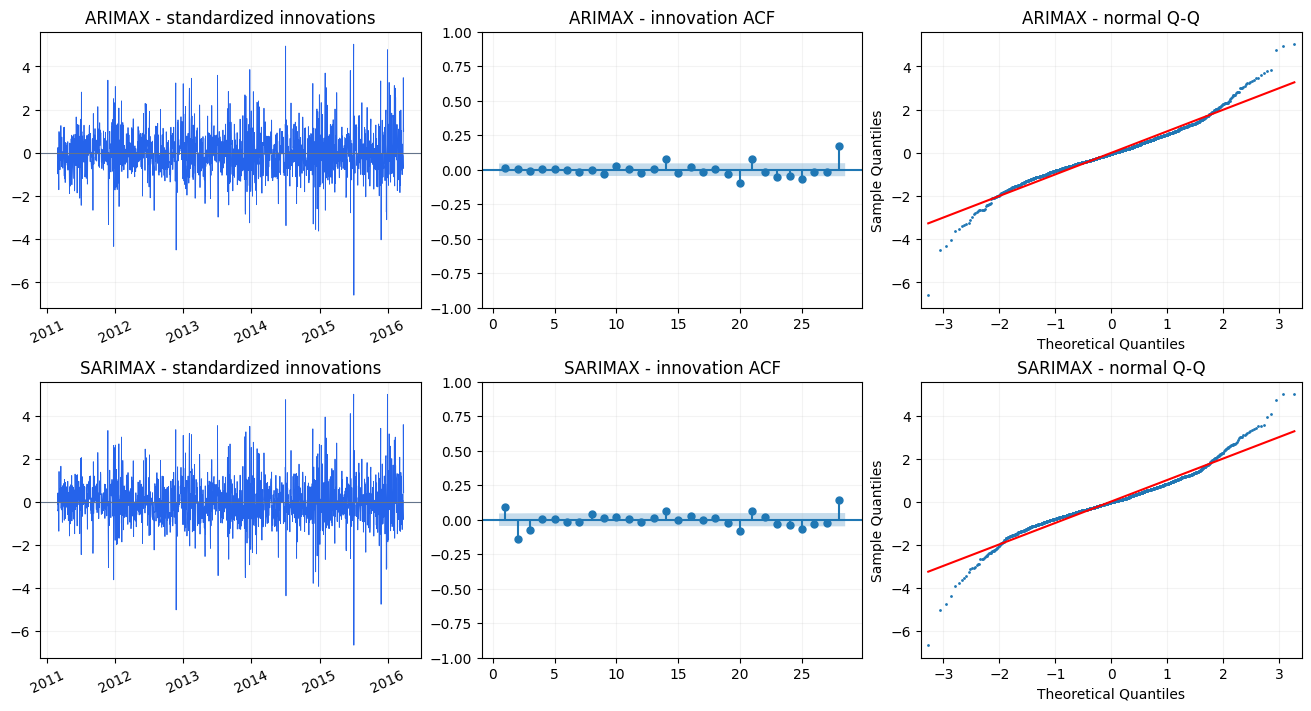

In [11]:
lb_rows, parameter_rows, fit_summaries = [], [], []
diagnostics = {}
fig_residuals, axes = plt.subplots(2, 3, figsize=(13, 7), layout='constrained')
for index, family in enumerate(['ARIMA', 'SARIMA']):
    cid = selected_external[family]
    fitted = validation_models[cid]['fit']
    label = family + 'X'
    burn = max(28, int(fitted.loglikelihood_burn))
    innovation = np.asarray(fitted.filter_results.standardized_forecasts_error[0])[burn:]
    model_df = int(max(0, fitted.df_model - fitted.k_diffuse_states - 1))
    require(np.isfinite(innovation).all() and min(LB_LAGS) > model_df,
            'Residual checks require finite innovations and positive adjusted degrees of freedom.')
    lb = acorr_ljungbox(innovation, lags=list(LB_LAGS), model_df=model_df, return_df=True)
    for lag, row in lb.iterrows():
        lb_rows.append({'model': label, 'config_id': cid, 'lag': int(lag),
                        'model_df': model_df, 'discarded_start_rows': burn,
                        'innovation_rows': len(innovation), 'lb_stat': float(row['lb_stat']),
                        'lb_pvalue': float(row['lb_pvalue']),
                        'reject_no_autocorrelation': bool(row['lb_pvalue'] < ALPHA)})
    intervals = np.asarray(fitted.conf_int(alpha=ALPHA))
    for j, name in enumerate(fitted.param_names):
        parameter_rows.append({'model': label, 'config_id': cid, 'parameter': name,
                               'estimate': float(fitted.params.iloc[j]),
                               'std_error': float(fitted.bse.iloc[j]),
                               'lower_95': float(intervals[j, 0]), 'upper_95': float(intervals[j, 1])})
    diagnostics[label] = {'model_df': model_df, 'innovation_rows': len(innovation),
                          'any_ljung_box_rejection': bool((lb['lb_pvalue'] < ALPHA).any())}
    fit_summaries.append(f'{label}: {cid}\n{fitted.summary()}\n')
    axes[index, 0].plot(development['date'].iloc[burn:1885], innovation,
                         color='#2563eb', linewidth=0.6)
    axes[index, 0].axhline(0, color='#64748b', linewidth=0.8)
    axes[index, 0].set_title(f'{label} - standardized innovations')
    axes[index, 0].tick_params(axis='x', labelrotation=25)
    plot_acf(innovation, lags=28, zero=False, alpha=ALPHA,
              ax=axes[index, 1], title=f'{label} - innovation ACF')
    qqplot(innovation, line='s', ax=axes[index, 2], marker='.', markersize=2)
    axes[index, 2].set_title(f'{label} - normal Q-Q')
    for ax in axes[index]:
        ax.grid(alpha=0.15)
ljung_box = pd.DataFrame(lb_rows)
parameters = pd.DataFrame(parameter_rows)
print(ljung_box.to_string(index=False, formatters={'lb_pvalue': lambda v: f'{v:.3e}'}))
plt.show()
plt.close(fig_residuals)

## 7. Visualize the ablation and Validation forecasts

The ablation bars show single Validation RMSSE values, not confidence
intervals. All variants remain in the saved
tables. The forecast plot includes selected external models and the weekly
SARIMA reference from the same origin; the baselines remain in the main table.

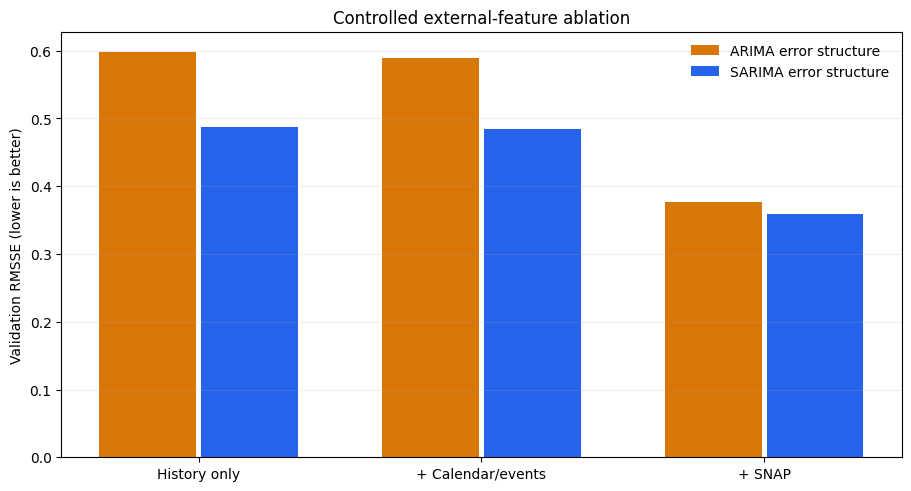

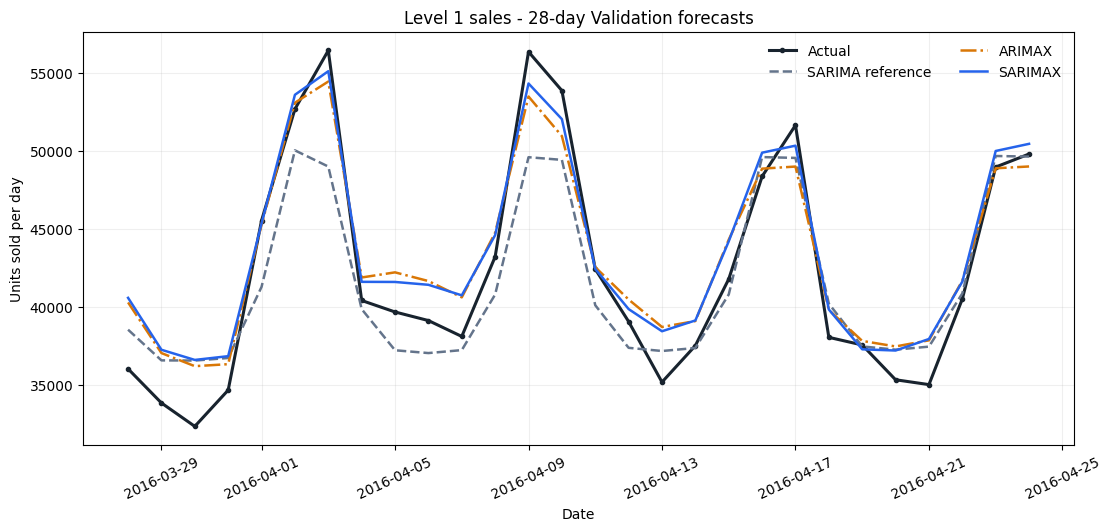

In [12]:
fig_ablation, ax = plt.subplots(figsize=(9, 4.8), layout='constrained')
positions = np.arange(3)
for offset, family, color in [(-0.18, 'ARIMA', '#d97706'), (0.18, 'SARIMA', '#2563eb')]:
    subset = ablation_summary[ablation_summary['family'] == family].set_index('feature_group')
    values = subset.reindex(FEATURE_GROUPS)['validation_rmsse']
    ax.bar(positions + offset, values, width=0.34, label=family + ' error structure', color=color)
ax.set_xticks(positions, ['History only', '+ Calendar/events', '+ SNAP'])
ax.set(ylabel='Validation RMSSE (lower is better)', title='Controlled external-feature ablation')
ax.legend(frameon=False)
ax.grid(axis='y', alpha=0.2)
plt.show()
plt.close(fig_ablation)

fig_validation, ax = plt.subplots(figsize=(11, 5.2), layout='constrained')
ax.plot(pd.to_datetime(frames['val']['date']), frames['val']['total_sales'],
        color='#18232e', marker='o', markersize=3, linewidth=2.2, label='Actual')
reference_id = next(row['config_id'] for row in variant_rows
                     if row['family'] == 'SARIMA' and row['feature_group'] == 'history_only')
plot_specs = [(reference_id, 'SARIMA reference', '#64748b', '--'),
              (selected_external['ARIMA'], 'ARIMAX', '#d97706', '-.'),
              (selected_external['SARIMA'], 'SARIMAX', '#2563eb', '-')]
for cid, label, color, style in plot_specs:
    subset = predictions[(predictions['fold'] == 3) & (predictions['config_id'] == cid)]
    ax.plot(pd.to_datetime(subset['date']), subset['prediction'],
            label=label, color=color, linestyle=style, linewidth=1.8)
ax.set(title='Level 1 sales - 28-day Validation forecasts', xlabel='Date', ylabel='Units sold per day')
ax.grid(alpha=0.2)
ax.legend(frameon=False, ncol=2)
ax.tick_params(axis='x', labelrotation=25)
plt.show()
plt.close(fig_validation)

## 8. Save the evidence and one download bundle

The bundle includes all fit outcomes, ablation/main summaries, feature inventory,
forecasts, coefficients, residual checks, figures, selected encoders and model
configurations. The saved schemas capture Train-only vocabulary, scaling and
identification decisions. Test is not opened, and no final Test refit is performed.

PASS confirms a complete comparison for the selected variants. Other failed
fits, if any, remain logged and are excluded; residual diagnostic rejections
remain visible. The development comparison cannot establish causality or
guarantee future accuracy.

In [13]:
table_dir = output_dir / '04_Outputs_and_Artifacts' / 'table'
figure_dir = output_dir / '04_Outputs_and_Artifacts' / 'figures'
prediction_dir = output_dir / '02_Data' / 'predictions'
for directory in [table_dir, figure_dir, prediction_dir]:
    directory.mkdir(parents=True, exist_ok=True)
paths = []
for name, table in [('exog_cv_scores.csv', cv_scores),
                    ('exog_ablation_summary.csv', ablation_summary),
                    ('exog_comparison_summary.csv', comparison_summary),
                    ('exog_feature_inventory.csv', feature_inventory),
                    ('exog_residual_ljung_box.csv', ljung_box),
                    ('exog_parameters.csv', parameters)]:
    path = table_dir / name
    table.to_csv(path, index=False, float_format='%.12g')
    paths.append(path)
prediction_path = prediction_dir / 'exog_cv_predictions.csv'
predictions.to_csv(prediction_path, index=False, float_format='%.12g')
paths.append(prediction_path)
for name, figure in [('exog_ablation_validation.png', fig_ablation),
                      ('exog_validation_forecasts.png', fig_validation),
                      ('exog_residual_diagnostics.png', fig_residuals)]:
    path = figure_dir / name
    figure.savefig(path, dpi=300, bbox_inches='tight')
    paths.append(path)
selected = []
for family in ['ARIMA', 'SARIMA']:
    cid = selected_external[family]
    selected.append({'model': family + 'X', 'config_id': cid,
                      'error_config': validation_models[cid]['base_config'],
                      'feature_schema': validation_models[cid]['schema']})
selected_manifest = {'source_config_sha256': SOURCE_CONFIG_SHA256,
                     'frozen_error_configs': BASE_CONFIGS, 'forecast_horizon': HORIZON,
                     'target_divisor': SALES_SCALE, 'selection_metric': 'Validation RMSSE',
                     'selected_models': selected, 'test_labels_read': False}
manifest_path = output_dir / '04_Outputs_and_Artifacts' / 'exog_selected_configurations.json'
manifest_path.write_text(json.dumps(selected_manifest, ensure_ascii=False, indent=2, allow_nan=False) + '\n')
paths.append(manifest_path)
summary_path = output_dir / '04_Outputs_and_Artifacts' / 'exog_fit_summaries.txt'
summary_path.write_text('\n'.join(fit_summaries), encoding='utf-8')
paths.append(summary_path)
statistical_scores = cv_scores[cv_scores['family'] != 'Baseline']
report = {
    'status': 'PASS', 'checked_at_utc': datetime.now(timezone.utc).isoformat(),
    'python': platform.python_version(), 'random_seed': SEED,
    'packages': {package: metadata.version(package) for package in
                 ['numpy', 'pandas', 'scipy', 'matplotlib', 'statsmodels', 'threadpoolctl']},
    'files_read': list(FILENAMES), 'test_labels_read': False, 'test_forecasts_computed': False,
    'data_fingerprints': {item['file']: item['table_sha256'] for item in input_inventory},
    'forecast_horizon': HORIZON, 'origins': list(ORIGINS), 'feature_groups': FEATURE_GROUPS,
    'frozen_error_configs': BASE_CONFIGS, 'source_config_sha256': SOURCE_CONFIG_SHA256,
    'feature_preprocessing': 'Vocabulary, identification and standardization fit on each observed prefix only',
    'external_input_columns': EXOG_INPUT_COLUMNS,
    'target_divisor': SALES_SCALE, 'optimizer_iteration_limits': list(MAX_ITERATIONS),
    'statistical_fit_count': len(statistical_scores),
    'excluded_fit_count': int((~statistical_scores['eligible']).sum()),
    'comparison_models': len(comparison_summary), 'forecast_records': len(predictions),
    'clipped_forecasts': int(eligible_scores['clipped_count'].sum()),
    'clipped_fraction': float(eligible_scores['clipped_count'].sum() / len(predictions)),
    'selected_models': selected, 'residual_diagnostics': diagnostics,
    'main_comparison': comparison_summary.to_dict(orient='records'),
    'limitations': [
        'Error orders are frozen; the joint model/feature search is not exhaustive.',
        'Calendar and events are added together, not isolated individually.',
        'Weekly deterministic regressors annihilated by seasonal differencing are not separately identified.',
        'The stability summary shares the feature-selection Validation window.',
        'Feature ablation measures predictive changes, not causal effects.',
        'Reference refits may have small optimizer differences from notebook 03.',
        'No independent Test result is reported.',
    ],
    'run_seconds_before_packaging': float(perf_counter() - RUN_STARTED),
}
report_path = output_dir / '04_Outputs_and_Artifacts' / 'exog_run_report.json'
report_path.write_text(json.dumps(report, ensure_ascii=False, indent=2, allow_nan=False) + '\n')
paths.append(report_path)
require(len(paths) == 13, 'Expected thirteen result files.')
archive_path = output_dir / '04_arimax_sarimax_results.zip'
with ZipFile(archive_path, 'w', compression=ZIP_DEFLATED) as archive:
    for path in paths:
        archive.write(path, arcname=path.relative_to(output_dir))
print('ARIMAX/SARIMAX CHECK PASSED')
print(f'Statistical fits: {len(statistical_scores)}; folds: 3; comparison models: {len(comparison_summary)}')
print(f'Forecast rows: {len(predictions)}; excluded fits: {report["excluded_fit_count"]}')
print(f'Download bundle: {archive_path.resolve()}')
print(comparison_summary[['model', 'config_id', 'validation_rmsse', 'mean_rmsse', 'std_rmsse']]
      .round(4).to_string(index=False))

ARIMAX/SARIMAX CHECK PASSED
Statistical fits: 18; folds: 3; comparison models: 8
Forecast rows: 840; excluded fits: 0
Download bundle: /kaggle/working/04_arimax_sarimax_results.zip
           model                                    config_id  validation_rmsse  mean_rmsse  std_rmsse
         SARIMAX sarima_1_1_1_1_1_1_7_n__calendar_events_snap            0.3589      0.4679     0.1511
          ARIMAX          arima_7_1_2_t__calendar_events_snap            0.3765      0.4922     0.1443
          SARIMA         sarima_1_1_1_1_1_1_7_n__history_only            0.4873      0.6030     0.1707
           ARIMA                  arima_7_1_2_t__history_only            0.5982      0.6040     0.0170
Seasonal Naive 7                             seasonal_naive_7            0.6677      0.7519     0.1542
          SMA-28                            moving_average_28            1.2001      1.1643     0.0603
           SMA-7                             moving_average_7            1.2165      1.2238     0.

## References

- Finalized IS403 project plan: T12, known calendar/event/SNAP inputs, temporal
  leakage prevention, and external-feature ablation.
- Course Chapter 5: ARIMAX/SARIMAX and regression with time-series errors.
- Hyndman & Athanasopoulos, *Forecasting: Principles and Practice*, Chapter 10:
  https://otexts.com/fpp3/dynamic-regression.html
- statsmodels official APIs:
  [ARIMA](https://www.statsmodels.org/stable/generated/statsmodels.tsa.arima.model.ARIMA.html),
  [SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html),
  [Residual tests](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAXResults.test_serial_correlation.html).